# Puzzle

https://thefiddler.substack.com/p/can-you-maximize-the-range

### This Week’s Fiddler
Suppose you have many fair dice. You roll them all at once, and then measure the range (i.e., the difference between the maximum and the minimum) of the resulting rolls. With sufficiently many dice, this range is almost always 5. But with fewer dice, getting a range of 5 is no longer a sure thing.

What is the smallest number of dice you need such that getting a range of 5 is more likely than not?

### This Week’s Extra Credit
Now suppose you are rolling 1000 dice. And you collectively roll those 1000 dice over and over again, a total of N times, each time keeping track of the sum of all 1000 dice.

When N is really, really large, the range for this data set is almost always 5000. But with smaller values of N, getting a range of 5000 is no longer a sure thing.

Once again, your task is to determine the smallest value of N such that getting a range of 5000 is more likely than not. As it so happens, this number is rather large, and can be written in scientific notation as A × 10^B, where B is an integer and 1 ≤ A < 10. Determine the values of A (to at least four decimal places) and B.

# Unified Setup

The Fiddler case is equivalent whether we roll N dice at once or roll one dice N times.

So, let D be the number of dice (1 in the fiddler case, 1000 in the extra credit case), and let N be the number of times we roll the D dice. And each time we calculate the sum of the D dice (range D to 6D).

Let A be the min event. i.e. all D dice are at the min value.

And similarly let B be the max event with all D dice at the max value.

$ a = P(A) = b  = P(B) = (1/6)^D = 1 / 6^D $  

Let S be the set of N rolls.

# f Calculations

Let $S_A$ be the event that S contains A.

Let $S_B$ be the event that S contains B.

Let F be the event that the range over the N rolls is the full range. i.e. S contains both an 'A' and a 'B'

$ f = P(F) = P(S_A \cap S_B)$

While there are many ways to calculate the value of f, a slightly indirect way makes the arithmetic simpler.

$ f = P(F) = 1 - P(\overline{F})$

$\overline{F}$ is the event that across N rolls we have either no A or no B or both.

$ \overline{F} = \overline{S_A} \cup \overline{S_B}$

$ P(\overline{F}) = P(\overline{S_A} \cup \overline{S_B})$

$ P(\overline{F}) = P(\overline{S_A}) + P(\overline{S_B}) - P(\overline{S_A} \cap \overline{S_B})$

Now, we can see relatively easily that 

$ P(\overline{S_A}) = (1-a)^N $

$ P(\overline{S_B}) = (1-b)^N $

$ P(\overline{S_A} \cap \overline{S_B}) = (1-a-b)^N $

Plugging that back in:

$ P(\overline{F}) = (1-a)^N + (1-b)^N - (1-a-b)^N $

And going one step back:

$ f = 1 - (1-a)^N - (1-b)^N + (1-a-b)^N $

And we can also put in the values of a and b to get:

$ f = 1 - (1-(1/6^D))^N - (1-(1/6^D))^N + (1-(1/6^D)-(1/6^D))^N $

$ f = 1 - 2 * ((6^D - 1)/6^D)^N + ((6^D-2)/6^D)^N $

$ f = [ 6^{DN} - 2 * (6^D - 1)^N + (6^D-2)^N ] / 6^{DN} $

# Understanding

That looks intimidating, but let's plug in D=1 to see what we get.

$f = 1 - 2 * (5/6)^N + (4/6)^N $

For N = 0, that becomes: 
$f = 1 -2  + 1 = 0$

For N = 1, that becomes: 
$f = 1 - 10/6  + 4/6 = 0$

For N = 2, that becomes: 
$f = 1 - 50/36  + 16/36 = 2/36$

For N = 3, that becomes: 
$f = 1 - 250/216  + 64/216 = 30/216 = 5/36$

So, the values for N=0,1,2 seem to be correct. N=3 is also plausible.

# Fiddler Solution

Let's first try to do this by hand.

$ f = [ 6^{DN} - 2 * (6^D - 1)^N + (6^D-2)^N ] / 6^{DN}  $

D = 1, so:

$ f = [ 6^{N} - 2 * (6 - 1)^N + (6-2)^N ] / 6^{N}  $

$ f = [ 6^{N} - 2 * 5^N + 4^N ] / 6^{N}  $

Plugging in f = 1/2, we get

$ 1/2 = [ 6^{N} - 2 * 5^N + 4^N ] / 6^{N}  $

$ 6^N = 2[ 6^{N} - 2 * 5^N + 4^N ]  $

$ 0 = 6^{N} - 4 * 5^N + 2 * 4^N  $

$ 4 * 5^N  = 6^{N} + 2 * 4^N  $

I am not sure how to solve this except by trying various values of N, i.e. numerically. The extra credit is going to need that even more.

So, let's go the whole way, and write some code.

In [83]:
from math import pow
def calc_f(N, D, offset=0):
    version = 2
    if version == 1:
        # $ f = 1 - 2 * ((6^D - 1)/6^D)^N + ((6^D-2)/6^D)^N $
        six_d = 6 ** D
        six_d_minus_1 = six_d - 1
        six_d_minus_2 = six_d - 2
        first_term = 1
        second_term = 2 * (six_d_minus_1 / six_d) ** N
        third_term = (six_d_minus_2 / six_d) ** N
        f = first_term - second_term + third_term - offset
    if version == 2:
        # $ f = 1 - (1-(1/6^D))^N - (1-(1/6^D))^N + (1-(1/6^D)-(1/6^D))^N $
        inv_six_d = 6 ** (-D)
        first_term = 1
        second_term = 2 * (1 - inv_six_d) ** N
        third_term = (1 - 2 * inv_six_d) ** N
        f = first_term - second_term + third_term - offset
    return f

In [87]:
def fiddler_f(N):
    return calc_f(N, 1, 0.5)

from scipy.optimize import fsolve

fiddler_solution = fsolve(fiddler_f, 7)

print(f"Fiddler solution: {fiddler_solution[0]}")    

Fiddler solution: 6.995331901435353


N=1, f=0.0
N=2, f=0.05555555555555547
N=3, f=0.13888888888888873
N=4, f=0.23302469135802462
N=5, f=0.32793209876543195
N=6, f=0.4179955418381343
N=7, f=0.5003643689986281
N=8, f=0.5738823635878676
N=9, f=0.638398895938119
N=10, f=0.694330364136141
N=11, f=0.7423850484608121
N=12, f=0.7833940370600287
N=13, f=0.818210473111814
N=14, f=0.8476523557454829


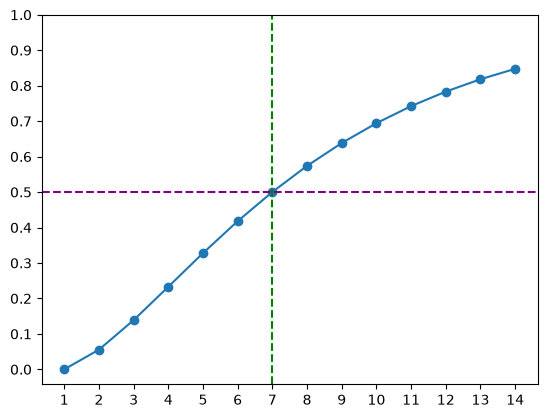

In [85]:
from matplotlib import pyplot as plt

fiddler_N_values = range(1, 15)
fiddler_f_values = [calc_f(N,1,0) for N in fiddler_N_values]

for N, f in zip(fiddler_N_values, fiddler_f_values):
    print(f"N={N}, f={f}")

plt.plot(fiddler_N_values, fiddler_f_values, marker='o')
plt.axhline(0.5, color='purple', linestyle='--', label='f=0.5')
plt.axvline(7, color='green', linestyle='--', label='N=7')
plt.xticks(fiddler_N_values)
plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
plt.show()

# Extra Credit Solution

We have:

$ f = 1 - (1-(1/6^D))^N - (1-(1/6^D))^N + (1-(1/6^D)-(1/6^D))^N $

$ f = 1 - 2 * (1-(1/6^D))^N + (1-2*(1/6^D))^N $

Let's denote $q = (1/6^D)$.

$ f = 1 - 2 (1-q)^N + (1-2q)^N $

Based on several false starts, we know a few things:
* Direct evaluation runs into issues, because we exceed the float64 range.
* The answer must have $N \propto 6^D$, because at small and large N, the formula simplifies to 0 and 1 respectively.

So, let's denote $N = r 6^D = r/q = 2r/2q$.

$ f = 1 - 2 (1-q)^{r/q} + (1-2q)^{2r/2q} $

$ f = 1 - 2 ((1-q)^{1/q})^r + ((1-2q)^{1/2q})^{2r} $

Now, since q is very small, we can use the [well known limit](https://www.google.com/search?q=limit+(1+-+x)%5E(1%2Fx))

$ \lim_{x \rightarrow 0} (1-x)^{1/x} = 1/e $

*[This is actually a very good approximation for our case. Even with D = 10, this is correct to 7 decimal digits (**0.3678794**381294 vs **0.3678794**411714 ), and we are using D = 1000.]*

So, we get:

$ f = 1 - 2 (1/e)^r + (1/e)^{2r} $

$ f = (1 - (1/e)^r)^{2} $

$ f = (1 - 1/e^r)^{2} $

Now, solving for f = 1/2 is easy.

$ (1 - 1/e^r)^{2} = 1/2$

$ 1 - 1/e^r = \pm  1/\sqrt{2}$

$ 1/e^r = 1 \pm  1/\sqrt{2}$

$ 1/e^r = (\sqrt{2} \pm  1)/\sqrt{2}$

$ e^r = \sqrt{2}/(\sqrt{2} \pm  1)$

$ r = ln (\sqrt{2}/(\sqrt{2} \pm  1))$

We want the positive r solution, which is achieved with the -1.

$ r = ln (\sqrt{2}/(\sqrt{2} -  1))$

And then: $N = r * 6^D.

Since this exceeds the float64 precision, we need to use the decimal module to get the value.

In [86]:
from decimal import Decimal, getcontext
getcontext().prec = 1000 # 1k places should be sufficient since 6^1000 < 10 ^1000

sqrt_2 = Decimal(2).sqrt()
sqrt_2_m_1 = sqrt_2 - Decimal(1)
ratio = sqrt_2 / sqrt_2_m_1
r = ratio.ln()
print(f"r = {r:.20f}")

N = r * (Decimal(6) ** Decimal(1000))

print(f"Extra credit solution: N={N:.20e}")

r = 1.22794717729951567994
Extra credit solution: N=1.73952257302732812274e+778


Note that while Decimal could print lots more digits, this is not a fully exact value since our 1/e approximation is correct to a large number of decimal places, but not fully exact.

# Conclusion

This was tricky - it needed a large sequence of good ideas and clear thinking to be solvable, without  much recourse to brute force options.

**Fiddler solution: N = 7 (smallest integer larger than 6.9953319)**

**Extra credit solution: N=1.73952257302732812274e+778 i.e. A = 1.73952257302732812274 and B = 778**